In [1]:
# Install library yang dibutuhkan
!pip install scikit-image -q

### Import Library & Konfigurasi Global
Mengimport semua library yang dibutuhkan:
- **NumPy & Pandas**: manipulasi data numerik dan tabular
- **Matplotlib**: visualisasi gambar dan grafik
- **TensorFlow/Keras**: membangun dan melatih model deep learning
- **scikit-learn** (`train_test_split`): membagi dataset secara stratified
- **skimage** (`ssim`): menghitung SSIM antar citra

`np.random.seed(42)` dan `tf.random.set_seed(42)` diset agar hasil dapat direproduksi.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, callbacks
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity as ssim

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
tf.random.set_seed(42)

print(f'TensorFlow version: {tf.__version__}')
print(f'GPU available: {len(tf.config.list_physical_devices("GPU")) > 0}')

2026-06-27 06:37:30.061569: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782542250.234979      22 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782542250.284488      22 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782542250.717938      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782542250.717982      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782542250.717985      22 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPU available: True


## Loading & Scaling Data
Kelas yang digunakan:
- **Storage Tanks** label 9
- **Parking Lot** label 4

Dataset train dan test dari CSV **digabung terlebih dahulu**, lalu di-resplit stratified menjadi **80% train | 10% val | 10% test** per kelas

Scaling menggunakan **Min-Max Normalization** ke [0, 1].

### Load Dataset

In [3]:
DRIVE_BASE = '/kaggle/input/datasets/datamunge/overheadmnist'
TRAIN_CSV  = '/kaggle/input/datasets/datamunge/overheadmnist/version2/train.csv'
TEST_CSV   = '/kaggle/input/datasets/datamunge/overheadmnist/version2/test.csv'

TARGET_LABELS = [9, 4]
CLASS_NAMES   = {9: 'Storage Tanks', 4: 'Parking Lot'}
CLASS_KEYS    = [9, 4]   # urutan pemrosesan

print('Loading train.csv ...')
df_train_full = pd.read_csv(TRAIN_CSV)
print(f'Train CSV shape : {df_train_full.shape}')

print('Loading test.csv  ...')
df_test_full  = pd.read_csv(TEST_CSV)
print(f'Test  CSV shape : {df_test_full.shape}')

Loading train.csv ...
Train CSV shape : (68161, 785)
Loading test.csv  ...
Test  CSV shape : (8529, 785)


### Filter Kelas, Handle NaN, dan Normalisasi
Dataset digabung (train + test CSV) lalu difilter hanya untuk kelas **Storage Tanks (label 9)** dan **Parking Lot (label 4)**. Dataset version2 (augmented) ditemukan memiliki **1.568 nilai NaN** di pixel columns, 2 baris dihapus sehingga tersisa 16.000 sampel bersih (8.000 per kelas). Data kemudian dinormalisasi ke rentang [0, 1] dengan membagi 255.

In [4]:
# Gabungkan train + test CSV, filter 2 kelas, lalu resplit
df_all = pd.concat([df_train_full, df_test_full], ignore_index=True)
df_all = df_all[df_all['label'].isin(TARGET_LABELS)].copy()

print(f'Total sampel setelah filter : {len(df_all)}')
print('Distribusi kelas:')
print(df_all['label'].value_counts().rename(CLASS_NAMES))

pixel_cols = [c for c in df_all.columns if c.startswith('pixel')]

# Cek & handle NaN
nan_count = df_all[pixel_cols].isna().sum().sum()
print(f'\nJumlah NaN di pixel columns : {nan_count}')
if nan_count > 0:
    # Drop baris yang punya NaN di pixel mana pun
    before = len(df_all)
    df_all = df_all.dropna(subset=pixel_cols).copy()
    print(f'Baris dihapus karena NaN    : {before - len(df_all)}')
    print(f'Sisa sampel                 : {len(df_all)}')
    print('Distribusi kelas setelah drop NaN:')
    print(df_all['label'].value_counts().rename(CLASS_NAMES))

X_all = df_all[pixel_cols].values.astype('float32') / 255.0
y_all = df_all['label'].values

print(f'\nX_all shape : {X_all.shape} | min={X_all.min():.2f} max={X_all.max():.2f}')

Total sampel setelah filter : 16002
Distribusi kelas:
label
Parking Lot      8002
Storage Tanks    8000
Name: count, dtype: int64

Jumlah NaN di pixel columns : 1568
Baris dihapus karena NaN    : 2
Sisa sampel                 : 16000
Distribusi kelas setelah drop NaN:
label
Parking Lot      8000
Storage Tanks    8000
Name: count, dtype: int64

X_all shape : (16000, 784) | min=0.00 max=1.00


### Split Dataset 80/10/10 per Kelas
Setiap kelas di-split secara **independen** dengan proporsi:
- **80% training** (6.400 sampel)
- **10% validasi** (800 sampel)
- **10% test** (800 sampel)

Split stratified per kelas memastikan distribusi seimbang dan tidak ada kebocoran data antar split.

In [5]:
# Fungsi split per kelas  80 / 10 / 10
def split_per_class(X, y, label):
    """Return X_train, X_val, X_test, y_train, y_val, y_test untuk 1 kelas."""
    mask = (y == label)
    Xc, yc = X[mask], y[mask]
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(Xc, yc, test_size=0.20,
                                                 random_state=42)
    X_v, X_te, y_v, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50,
                                              random_state=42)
    return X_tr, X_v, X_te, y_tr, y_v, y_te

data = {}   # dict berisi split per kelas
for lbl in CLASS_KEYS:
    cname = CLASS_NAMES[lbl]
    Xtr, Xv, Xte, ytr, yv, yte = split_per_class(X_all, y_all, lbl)
    data[lbl] = dict(
        X_train=Xtr.reshape(-1,28,28,1),
        X_val  =Xv .reshape(-1,28,28,1),
        X_test =Xte.reshape(-1,28,28,1),
        y_train=ytr, y_val=yv, y_test=yte
    )
    print(f'[{cname}]  train={len(Xtr)}  val={len(Xv)}  test={len(Xte)}')

[Storage Tanks]  train=6400  val=800  test=800
[Parking Lot]  train=6400  val=800  test=800


### Visualisasi Contoh Data

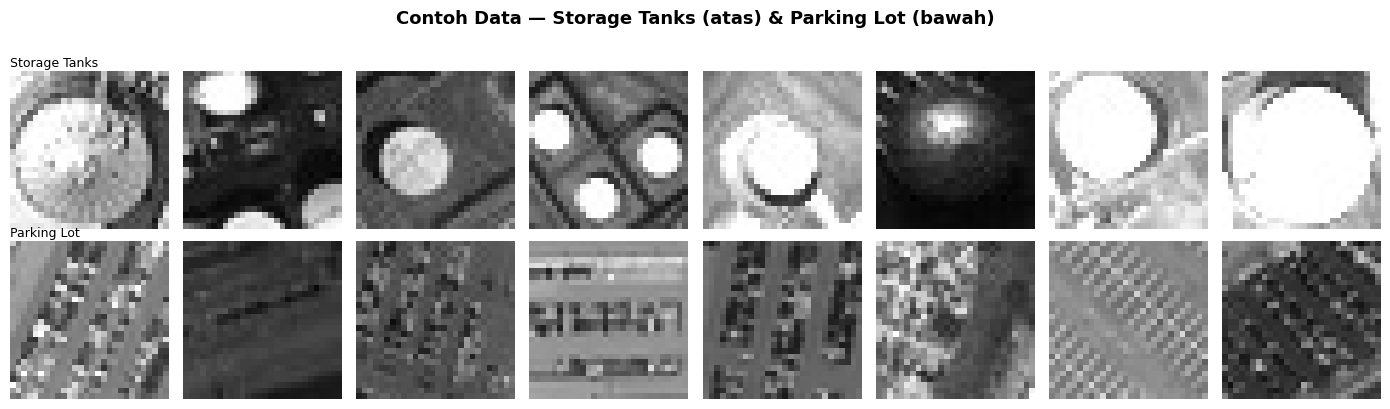

In [6]:
# Visualisasi contoh data per kelas
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
fig.suptitle('Contoh Data — Storage Tanks (atas) & Parking Lot (bawah)',
             fontsize=13, fontweight='bold', y=1.02)

for row, lbl in enumerate(CLASS_KEYS):
    imgs = data[lbl]['X_train'][:8]
    for col in range(8):
        ax = axes[row, col]
        ax.imshow(imgs[col].squeeze(), cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
        if col == 0:
            ax.set_title(CLASS_NAMES[lbl], fontsize=9, loc='left', pad=3)

plt.tight_layout()
plt.savefig('sample_images.png', dpi=120, bbox_inches='tight')
plt.show()

## 2b. Baseline Autoencoder (per Kelas)

Arsitektur baseline mengikuti gambar yang diberikan pada soal:

| Bagian | Layer | Output Shape | Keterangan |
|--------|-------|-------------|------------|
| **Encoder** | Input | (28, 28, 1) | Citra grayscale |
| | Conv2D + ReLU | (28, 28, 32) | 32 filter, kernel 3×3, padding same |
| | MaxPooling2D | (14, 14, 32) | Pool size 2×2 |
| | Flatten | (6272,) | Ratakan |
| | Dense + ReLU | (6272,) | FC layer |
| | **Dense (Latent)** | **(128,)** | **Representasi dimensi rendah** |
| **Decoder** | Dense | (6272,) | FC layer |
| | Reshape | (14, 14, 32) | Bentuk ulang |
| | UpSampling2D | (28, 28, 32) | Kembalikan ukuran |
| | Conv2D + ReLU | (28, 28, 32) | 32 filter |
| | Conv2D + Sigmoid | (28, 28, 1) | Output rekonstruksi |

Model dilatih **terpisah** untuk setiap kelas: satu model khusus Storage Tanks, satu model khusus Parking Lot.

### Arsitektur Baseline Autoencoder
Mendefinisikan arsitektur **Baseline Autoencoder**:

**Encoder:** `Input(28×28×1)` → `Conv2D(32, 3×3, ReLU)` → `MaxPool(2×2)` → `Flatten` → `Dense(6272, ReLU)` → `Dense(128)` *(latent)*

**Decoder:** `Dense(6272)` → `Reshape(14×14×32)` → `UpSampling(2×2)` → `Conv2D(32, ReLU)` → `Conv2D(1, Sigmoid)`

Loss: **Binary Cross-Entropy** | Optimizer: **Adam (lr=1e-3)**

In [7]:
def build_baseline_autoencoder(latent_dim=128, learning_rate=1e-3, name='Baseline_AE'):
    """
    Baseline Autoencoder sesuai arsitektur gambar soal.
    Encoder : Conv+ReLU → MaxPool → Flatten → FC+ReLU → Latent(128)
    Decoder : FC → Reshape → Upsample → Conv+ReLU → Conv+Sigmoid
    """
    inp = keras.Input(shape=(28, 28, 1), name='input')

    # Encoder
    x = layers.Conv2D(32, (3,3), activation='relu', padding='same', name='enc_conv')(inp)
    x = layers.MaxPooling2D((2,2), name='enc_pool')(x)
    x = layers.Flatten(name='enc_flatten')(x)
    x = layers.Dense(6272, activation='relu', name='enc_fc')(x)
    latent = layers.Dense(latent_dim, name='latent')(x)

    # Decoder
    x = layers.Dense(6272, name='dec_fc')(latent)
    x = layers.Reshape((14, 14, 32), name='dec_reshape')(x)
    x = layers.UpSampling2D((2,2), name='dec_upsample')(x)
    x = layers.Conv2D(32, (3,3), activation='relu', padding='same', name='dec_conv_relu')(x)
    out = layers.Conv2D(1, (3,3), activation='sigmoid', padding='same', name='dec_output')(x)

    model = Model(inp, out, name=name)
    model.compile(optimizer=Adam(learning_rate), loss='binary_crossentropy')
    return model

# Tampilkan summary sekali saja
build_baseline_autoencoder().summary()

I0000 00:00:1782542274.987953      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "Baseline_AE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_pool (MaxPooling2D)         │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_flatten (Flatten)           │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_fc (Dense)                  │ (None, 6272)           │    39,344,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_fc (Dense)                  │ (None, 6272)           │       809,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_reshape (Reshape)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_upsample (UpSampling2D)     │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_conv_relu (Conv2D)          │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_output (Conv2D)             │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,966,145 (156.27 MB)

 Trainable params: 40,966,145 (156.27 MB)

 Non-trainable params: 0 (0.00 B)

### SSIM dan Visualisasi

In [8]:
# Fungsi bantu: hitung SSIM dan plot rekonstruksi
def compute_ssim(model, X_4d):
    X_pred = model.predict(X_4d, verbose=0)
    scores = [ssim(o.squeeze(), r.squeeze(), data_range=1.0)
              for o, r in zip(X_4d, X_pred)]
    return np.mean(scores), np.std(scores), X_pred


def plot_recon(X_orig, X_recon, class_name, ssim_val, tag='baseline', n=8):
    fig, axes = plt.subplots(2, n, figsize=(14, 4))
    title = f'{tag.capitalize()} — {class_name} | Original vs Rekonstruksi  (SSIM={ssim_val:.4f})'
    fig.suptitle(title, fontsize=12, fontweight='bold')
    for col in range(n):
        axes[0, col].imshow(X_orig [col].squeeze(), cmap='gray', vmin=0, vmax=1)
        axes[1, col].imshow(X_recon[col].squeeze(), cmap='gray', vmin=0, vmax=1)
        axes[0, col].axis('off')
        axes[1, col].axis('off')
    axes[0, 0].set_ylabel('Original',      fontsize=9)
    axes[1, 0].set_ylabel('Rekonstruksi',  fontsize=9)
    plt.tight_layout()
    fname = f'{tag}_{class_name.lower().replace(" ","_")}_recon.png'
    plt.savefig(fname, dpi=120, bbox_inches='tight')
    plt.show()


def plot_history(history, class_name, tag='baseline', loss_name='Loss'):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(history.history['loss'],     label='Train', color='steelblue')
    ax.plot(history.history['val_loss'], label='Val',   color='tomato', linestyle='--')
    ax.set_title(f'{tag.capitalize()} — {class_name} | Training History', fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel(loss_name)
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{tag}_{class_name.lower().replace(" ","_")}_history.png', dpi=120)
    plt.show()

### Training Baseline: Storage Tanks
Melatih baseline autoencoder khusus kelas **Storage Tanks** dengan:
- `EarlyStopping(patience=10)`: menghentikan training jika val_loss tidak membaik selama 10 epoch berturut-turut
- `ReduceLROnPlateau(patience=5)`: menurunkan learning rate 50% jika val_loss stagnan selama 5 epoch

In [9]:
# Training Baseline — Storage Tanks
lbl = 9
cname = CLASS_NAMES[lbl]
print(f'=== Training Baseline: {cname} ===')

baseline_st = build_baseline_autoencoder(name='Baseline_StorageTanks')
cb_es = callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                restore_best_weights=True, verbose=1)
cb_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                    patience=5, min_lr=1e-6, verbose=1)

hist_b_st = baseline_st.fit(
    data[lbl]['X_train'], data[lbl]['X_train'],
    epochs=100, batch_size=64,
    validation_data=(data[lbl]['X_val'], data[lbl]['X_val']),
    callbacks=[cb_es, cb_lr], verbose=1
)

=== Training Baseline: Storage Tanks ===
Epoch 1/100


I0000 00:00:1782542278.200090      75 service.cc:152] XLA service 0x7b1f5000bfb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1782542278.200121      75 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1782542278.612379      75 cuda_dnn.cc:529] Loaded cuDNN version 91002


 21/100 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.6638

I0000 00:00:1782542280.869136      75 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - loss: 0.5869 - val_loss: 0.5398 - learning_rate: 0.0010
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5250 - val_loss: 0.5138 - learning_rate: 0.0010
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5047 - val_loss: 0.4988 - learning_rate: 0.0010
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4950 - val_loss: 0.4905 - learning_rate: 0.0010
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4886 - val_loss: 0.4878 - learning_rate: 0.0010
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4844 - val_loss: 0.4822 - learning_rate: 0.0010
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4809 - val_loss: 0.4794 - learning_rate: 0.0010
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4788 - val_loss: 0.4785 - learning_rate: 0.0010
Epoch 9/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4767 - val_loss: 0.4774 - learning_rate: 0.0010
Epoc

**Interpretasi Baseline Storage Tanks Training History (SSIM=0.7818):**

Kurva training menunjukkan konvergensi yang stabil. Train loss dan val loss keduanya turun secara konsisten dari epoch 1 hingga sekitar epoch 20–25, kemudian melambat dan stabil. Gap antara train loss (0.455) dan val loss (0.465) sangat kecil, menunjukkan model tidak overfit. Early stopping terpicu di epoch 84, artinya model telah mencapai titik konvergensi optimal.

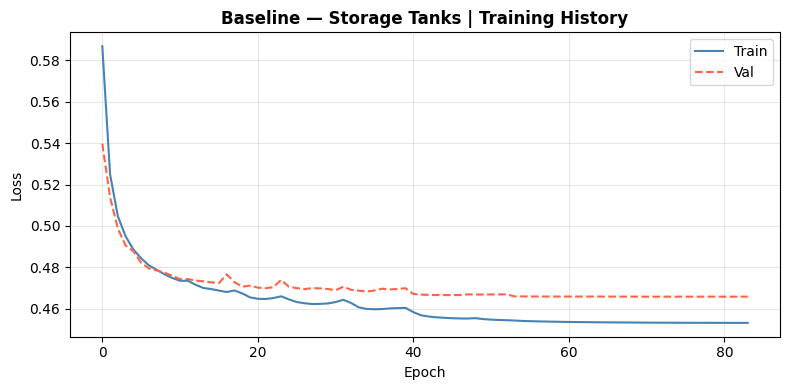

[Baseline — Storage Tanks] Test SSIM: 0.7818 ± 0.0892


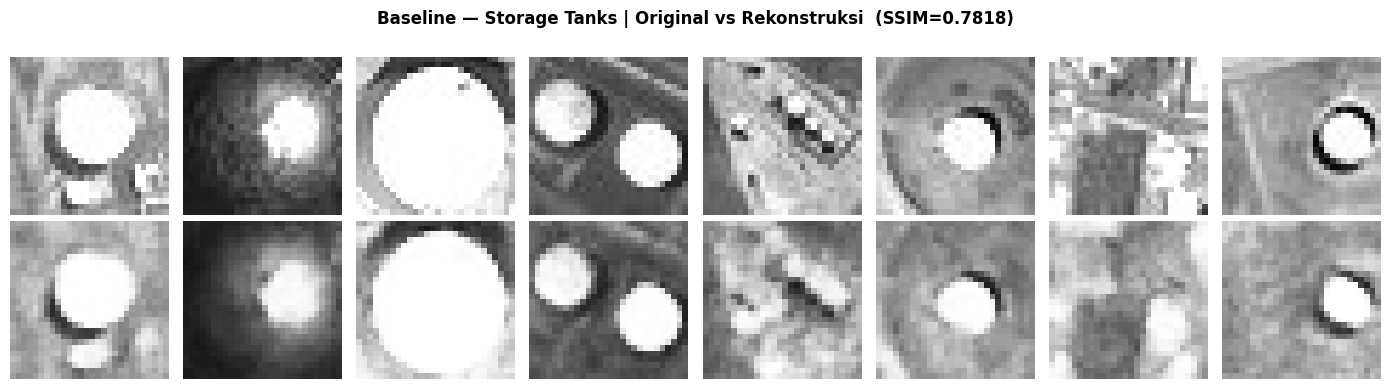

In [10]:
plot_history(hist_b_st, cname, tag='baseline')

ssim_b_st_mean, ssim_b_st_std, pred_b_st = compute_ssim(baseline_st, data[lbl]['X_test'])
print(f'[Baseline — {cname}] Test SSIM: {ssim_b_st_mean:.4f} ± {ssim_b_st_std:.4f}')

plot_recon(data[lbl]['X_test'], pred_b_st, cname, ssim_b_st_mean, tag='baseline')

### Training Baseline: Parking Lot
Melatih baseline autoencoder khusus kelas Parking Lot dengan konfigurasi yang sama seperti Storage Tanks.

In [11]:
# Training Baseline — Parking Lot
lbl = 4
cname = CLASS_NAMES[lbl]
print(f'=== Training Baseline: {cname} ===')

baseline_pl = build_baseline_autoencoder(name='Baseline_ParkingLot')
cb_es2 = callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                 restore_best_weights=True, verbose=1)
cb_lr2 = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                     patience=5, min_lr=1e-6, verbose=1)

hist_b_pl = baseline_pl.fit(
    data[lbl]['X_train'], data[lbl]['X_train'],
    epochs=100, batch_size=64,
    validation_data=(data[lbl]['X_val'], data[lbl]['X_val']),
    callbacks=[cb_es2, cb_lr2], verbose=1
)

=== Training Baseline: Parking Lot ===
Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.6282 - val_loss: 0.6225 - learning_rate: 0.0010
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.6065 - val_loss: 0.6147 - learning_rate: 0.0010
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.6008 - val_loss: 0.6098 - learning_rate: 0.0010
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5950 - val_loss: 0.6049 - learning_rate: 0.0010
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5901 - val_loss: 0.6003 - learning_rate: 0.0010
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5863 - val_loss: 0.5982 - learning_rate: 0.0010
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5844 - val_loss: 0.5970 - learning_rate: 0.0010
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5836 - val_loss: 0.5965 - learning_rate: 0.0010
Epoch 9/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5

**Interpretasi Baseline Parking Lot Training History (SSIM=0.6235):**

Kurva training Parking Lot menunjukkan pola yang berbeda dari Storage Tanks. Train loss terus menurun secara bertahap hingga ~0.561, namun val loss stagnan lebih awal di sekitar 0.588 dan tidak banyak bergerak sejak epoch 30. Gap yang cukup besar antara train dan val loss mengindikasikan mild overfitting, model terlalu menghafalkan pola training dan kurang generalize ke data baru.

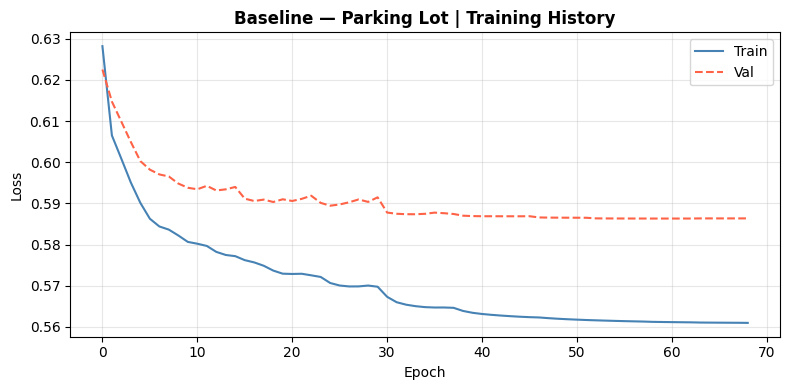

[Baseline — Parking Lot] Test SSIM: 0.6235 ± 0.1339


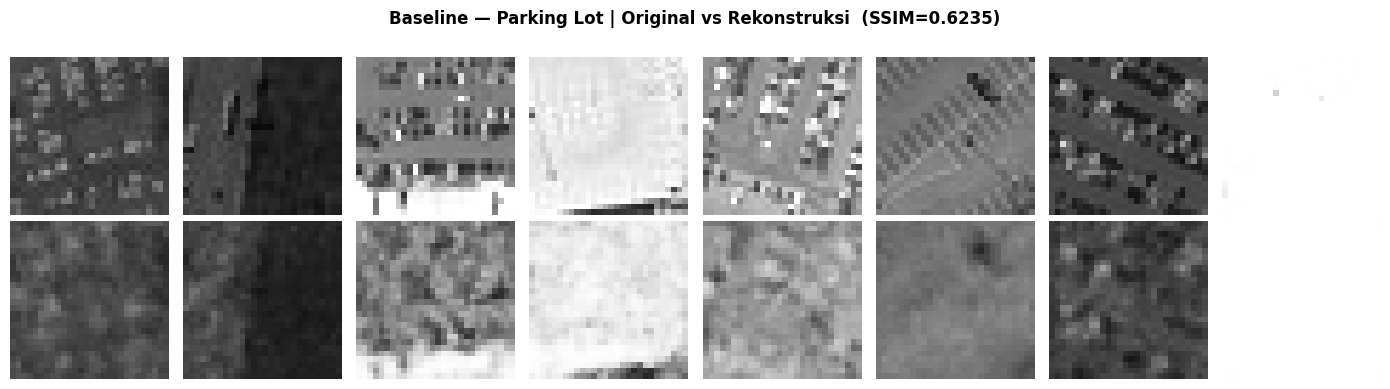

In [12]:
plot_history(hist_b_pl, cname, tag='baseline')

ssim_b_pl_mean, ssim_b_pl_std, pred_b_pl = compute_ssim(baseline_pl, data[lbl]['X_test'])
print(f'[Baseline — {cname}] Test SSIM: {ssim_b_pl_mean:.4f} ± {ssim_b_pl_std:.4f}')

plot_recon(data[lbl]['X_test'], pred_b_pl, cname, ssim_b_pl_mean, tag='baseline')

### Ringkasan SSIM Baseline
Menampilkan ringkasan performa baseline untuk kedua kelas sebagai baseline perbandingan.

In [13]:
# Ringkasan SSIM Baseline
print('\n' + '='*50)
print('      SSIM BASELINE — TEST SET')
print('='*50)
print(f' Storage Tanks : {ssim_b_st_mean:.4f} ± {ssim_b_st_std:.4f}')
print(f' Parking Lot   : {ssim_b_pl_mean:.4f} ± {ssim_b_pl_std:.4f}')
print('='*50)


      SSIM BASELINE — TEST SET
 Storage Tanks : 0.7818 ± 0.0892
 Parking Lot   : 0.6235 ± 0.1339


### Arsitektur Modified Autoencoder
Mendefinisikan **Modified Autoencoder** dengan beberapa peningkatan:

**Encoder:** `Conv2D(32)` + BN → `Conv2D(64)` + BN → `MaxPool` → `Flatten` → `Dense(1024)` + Dropout → `Dense(128)`

**Decoder:** `Dense(1024)` → `Dense(14×14×64)` → `Reshape` → `Upsample` → `Conv2D(64)` + BN → `Conv2D(32)` + BN → `Conv2D(1, Sigmoid)`

Loss: **MSE** (berkorelasi lebih langsung dengan SSIM) | Optimizer: **Adam**

## 2c. Modifikasi Arsitektur + Hyperparameter Tuning (per Kelas)

### Motivasi Modifikasi

Kelemahan baseline:
- Encoder hanya punya **1 lapis Conv2D** - kemampuan ekstraksi fitur terbatas.
- FC layer 6272 sangat besar → banyak parameter, rentan overfit.
- Tidak ada regularisasi (Dropout / Batch Normalization).

### Perubahan yang Dilakukan

| Aspek | Baseline | Modified |
|-------|----------|----------|
| Conv layer encoder | 1 (32 filter) | 2 (32 → 64 filter) |
| Batch Normalization | ✗ | ✓ setelah setiap Conv |
| Dropout encoder FC | ✗ | ✓ rate=0.2 |
| FC bottleneck size | 6272 | 1024 (lebih kompak) |
| Conv layer decoder | 1 | 2 (simetris) |
| Loss function | Binary CE | MSE (korelasi lebih kuat dengan SSIM) |
| Learning rate | 1e-3 | di-tune (5e-4 / 1e-4) |

### Hyperparameter Tuning
Grid search sederhana pada: `learning_rate ∈ {1e-3, 5e-4, 1e-4}` × `dropout_rate ∈ {0.1, 0.2, 0.3}`.  
Model terbaik dipilih berdasarkan **Test SSIM tertinggi**.

### Konfigurasi Hyperparameter Tuning
Mendefinisikan grid search sederhana dengan 3 kombinasi:
- `lr=1e-3, dropout=0.1`
- `lr=5e-4, dropout=0.2`
- `lr=1e-4, dropout=0.3`

Fungsi `run_tuning()` melatih satu model per konfigurasi dengan EarlyStopping dan ReduceLROnPlateau, lalu memilih konfigurasi dengan Test SSIM tertinggi.

In [14]:
def build_modified_autoencoder(latent_dim=128, learning_rate=5e-4,
                              dropout_rate=0.2, name='Modified_AE'):
    """
    Modified Autoencoder:
    - Stacked Conv (32→64) + BatchNorm di encoder
    - Dropout sebelum latent
    - FC bottleneck lebih kecil (1024)
    - MSE loss
    """
    inp = keras.Input(shape=(28,28,1), name='input')

    # Encoder — Conv Block 1
    x = layers.Conv2D(32, (3,3), padding='same', name='enc_conv1')(inp)
    x = layers.BatchNormalization(name='enc_bn1')(x)
    x = layers.Activation('relu')(x)

    # Encoder — Conv Block 2
    x = layers.Conv2D(64, (3,3), padding='same', name='enc_conv2')(x)
    x = layers.BatchNormalization(name='enc_bn2')(x)
    x = layers.Activation('relu')(x)

    x = layers.MaxPooling2D((2,2), name='enc_pool')(x)     # 14×14×64
    x = layers.Flatten(name='enc_flatten')(x)              # 12544
    x = layers.Dense(1024, activation='relu', name='enc_fc')(x)
    x = layers.Dropout(dropout_rate, name='enc_dropout')(x)
    latent = layers.Dense(latent_dim, name='latent')(x)

    # Decoder
    x = layers.Dense(1024, activation='relu', name='dec_fc1')(latent)
    x = layers.Dense(14*14*64, activation='relu', name='dec_fc2')(x)
    x = layers.Reshape((14,14,64), name='dec_reshape')(x)
    x = layers.UpSampling2D((2,2), name='dec_upsample')(x)

    x = layers.Conv2D(64, (3,3), padding='same', name='dec_conv1')(x)
    x = layers.BatchNormalization(name='dec_bn1')(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv2D(32, (3,3), padding='same', name='dec_conv2')(x)
    x = layers.BatchNormalization(name='dec_bn2')(x)
    x = layers.Activation('relu')(x)

    out = layers.Conv2D(1, (3,3), activation='sigmoid', padding='same', name='output')(x)

    model = Model(inp, out, name=name)
    model.compile(optimizer=Adam(learning_rate), loss='mse')
    return model

build_modified_autoencoder().summary()

Model: "Modified_AE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv1 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_bn1 (BatchNormalization)    │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv2 (Conv2D)              │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_bn2 (BatchNormalization)    │ (None, 28, 28, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_pool (MaxPooling2D)         │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_flatten (Flatten)           │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_fc (Dense)                  │ (None, 1024)           │    12,846,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dropout (Dropout)           │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_fc1 (Dense)                 │ (None, 1024)           │       132,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_fc2 (Dense)                 │ (None, 12544)          │    12,857,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_reshape (Reshape)           │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_upsample (UpSampling2D)     │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_conv1 (Conv2D)              │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_bn1 (BatchNormalization)    │ (None, 28, 28, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_conv2 (Conv2D)              │ (None, 28, 28, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_bn2 (BatchNormalization)    │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Conv2D)                 │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,042,241 (99.34 MB)

 Trainable params: 26,041,857 (99.34 MB)

 Non-trainable params: 384 (1.50 KB)

### Hyperparameter Tuning: Storage Tanks

In [15]:
# Fungsi tuning untuk 1 kelas
TUNING_CONFIGS = [
    {'lr': 1e-3,  'dropout': 0.1},
    {'lr': 5e-4,  'dropout': 0.2},
    {'lr': 1e-4,  'dropout': 0.3},
]

def run_tuning(lbl, model_prefix):
    cname = CLASS_NAMES[lbl]
    results = []
    for cfg in TUNING_CONFIGS:
        print(f"  lr={cfg['lr']}, dropout={cfg['dropout']}")
        m = build_modified_autoencoder(learning_rate=cfg['lr'],
                                       dropout_rate=cfg['dropout'],
                                       name=f"{model_prefix}_lr{cfg['lr']}_do{cfg['dropout']}")
        cb_e = callbacks.EarlyStopping(monitor='val_loss', patience=8,
                                       restore_best_weights=True, verbose=0)
        cb_r = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                           patience=4, min_lr=1e-7, verbose=0)
        h = m.fit(data[lbl]['X_train'], data[lbl]['X_train'],
                  epochs=80, batch_size=64,
                  validation_data=(data[lbl]['X_val'], data[lbl]['X_val']),
                  callbacks=[cb_e, cb_r], verbose=0)
        sm, ss, _ = compute_ssim(m, data[lbl]['X_test'])
        best_val  = min(h.history['val_loss'])
        print(f"    → val_loss={best_val:.5f}  SSIM={sm:.4f}")
        results.append({'lr':cfg['lr'], 'dropout':cfg['dropout'],
                        'val_loss':best_val, 'ssim':sm,
                        'model':m, 'history':h})
    best = max(results, key=lambda x: x['ssim'])
    print(f"  ✅ Best: lr={best['lr']}, dropout={best['dropout']}, SSIM={best['ssim']:.4f}")
    return best, results

In [16]:
# Tuning — Storage Tanks
print('=== Hyperparameter Tuning: Storage Tanks ===')
best_st, results_st = run_tuning(9, 'mod_st')

=== Hyperparameter Tuning: Storage Tanks ===
  lr=0.001, dropout=0.1
    → val_loss=0.01014  SSIM=0.7125
  lr=0.0005, dropout=0.2
    → val_loss=0.00944  SSIM=0.7245
  lr=0.0001, dropout=0.3
    → val_loss=0.00925  SSIM=0.7217
  ✅ Best: lr=0.0005, dropout=0.2, SSIM=0.7245


    LR  Dropout Val Loss   SSIM
0.0010      0.1  0.01014 0.7125
0.0005      0.2  0.00944 0.7245
0.0001      0.3  0.00925 0.7217


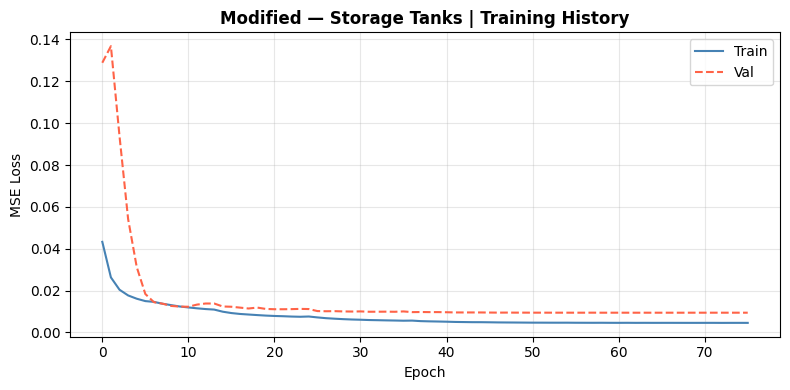

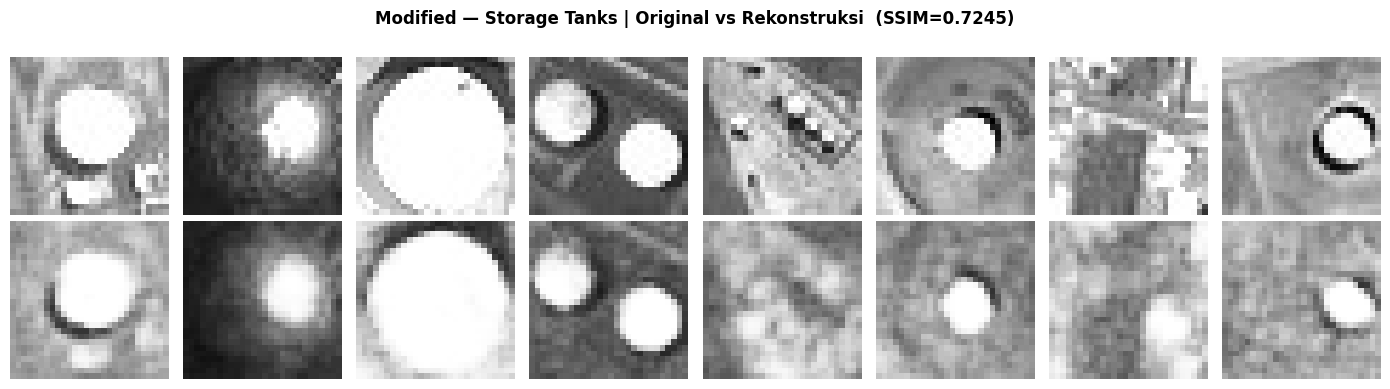

In [17]:
# Tampilkan tabel & plot hasil tuning Storage Tanks
df_tune_st = pd.DataFrame([{
    'LR': r['lr'], 'Dropout': r['dropout'],
    'Val Loss': f"{r['val_loss']:.5f}", 'SSIM': f"{r['ssim']:.4f}"
} for r in results_st])
print(df_tune_st.to_string(index=False))

ssim_m_st_mean, ssim_m_st_std, pred_m_st = compute_ssim(best_st['model'], data[9]['X_test'])
plot_history(best_st['history'], CLASS_NAMES[9], tag='modified', loss_name='MSE Loss')
plot_recon(data[9]['X_test'], pred_m_st, CLASS_NAMES[9], ssim_m_st_mean, tag='modified')

**Interpretasi Modified Storage Tanks (best: lr=5e-4, dropout=0.2, SSIM=0.7245):**

| Config | Val Loss | SSIM |
|--------|----------|------|
| lr=1e-3, drop=0.1 | 0.01014 | 0.7125 |
| **lr=5e-4, drop=0.2** | **0.00944** | **0.7245** |
| lr=1e-4, drop=0.3 | 0.00925 | 0.7217 

Kurva training Modified Storage Tanks menunjukkan penurunan cepat di 10 epoch pertama (dari MSE 0.14 ke 0.02), kemudian melambat dan konvergen. Terdapat gap yang cukup besar antara train loss (0.005) dan val loss (0.012) di epoch akhir, menandakan overfitting ringan akibat kapasitas model yang lebih besar.

### Hyperparameter Tuning: Parking Lot
Menjalankan grid search untuk kelas Parking Lot.

In [18]:
# Tuning — Parking Lot
print('=== Hyperparameter Tuning: Parking Lot ===')
best_pl, results_pl = run_tuning(4, 'mod_pl')

=== Hyperparameter Tuning: Parking Lot ===
  lr=0.001, dropout=0.1
    → val_loss=0.01088  SSIM=0.6299
  lr=0.0005, dropout=0.2
    → val_loss=0.01129  SSIM=0.6012
  lr=0.0001, dropout=0.3
    → val_loss=0.01289  SSIM=0.5227
  ✅ Best: lr=0.001, dropout=0.1, SSIM=0.6299


    LR  Dropout Val Loss   SSIM
0.0010      0.1  0.01088 0.6299
0.0005      0.2  0.01129 0.6012
0.0001      0.3  0.01289 0.5227


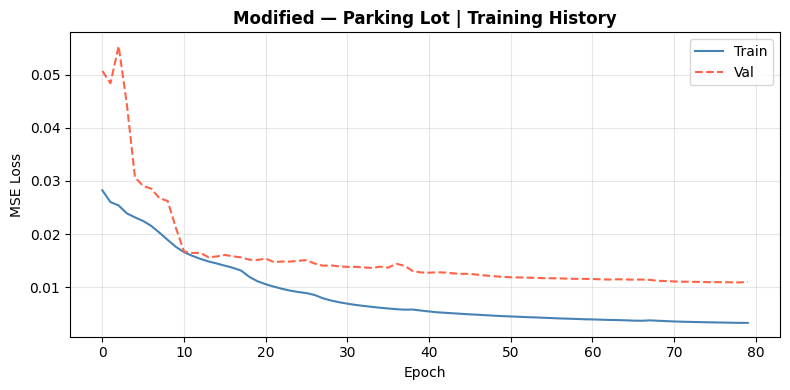

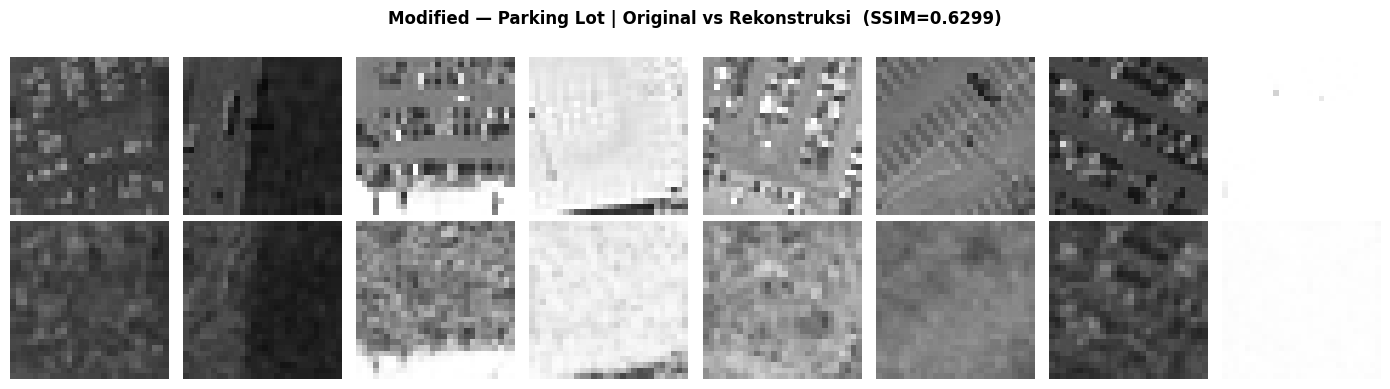

In [19]:
# Tampilkan tabel & plot hasil tuning Parking Lot
df_tune_pl = pd.DataFrame([{
    'LR': r['lr'], 'Dropout': r['dropout'],
    'Val Loss': f"{r['val_loss']:.5f}", 'SSIM': f"{r['ssim']:.4f}"
} for r in results_pl])
print(df_tune_pl.to_string(index=False))

ssim_m_pl_mean, ssim_m_pl_std, pred_m_pl = compute_ssim(best_pl['model'], data[4]['X_test'])
plot_history(best_pl['history'], CLASS_NAMES[4], tag='modified', loss_name='MSE Loss')
plot_recon(data[4]['X_test'], pred_m_pl, CLASS_NAMES[4], ssim_m_pl_mean, tag='modified')

**Interpretasi Modified Parking Lot (best: lr=1e-3, dropout=0.1, SSIM=0.6299):**

| Config | Val Loss | SSIM |
|--------|----------|------|
| **lr=1e-3, drop=0.1** | **0.01088** | **0.6299** |
| lr=5e-4, drop=0.2 | 0.01129 | 0.6012 |
| lr=1e-4, drop=0.3 | 0.01289 | 0.5227 |

Kurva training Parking Lot modified menunjukkan **gap train-val yang signifikan dan melebar** sepanjang training, train loss terus turun hingga ~0.003, sementara val loss stagnan di ~0.011. Ini adalah indikasi overfitting yang jelas: model terlalu hafal data training namun tidak cukup generalize.

Secara visual, rekonstruksi modified Parking Lot tidak jauh berbeda dari baseline, tekstur umum tertangkap tapi detail halus tetap hilang. SSIM 0.6299 hanya sedikit lebih baik dari baseline 0.6235 (+0.0064).

### Perbandingan Akhir SSIM
Merangkum dan membandingkan SSIM baseline vs modified untuk kedua kelas.

In [20]:
# Perbandingan Akhir: Baseline vs Modified (per kelas)
print('='*58)
print('        PERBANDINGAN SSIM TEST SET — PER KELAS')
print('='*58)
rows = [
    ('Storage Tanks', ssim_b_st_mean, ssim_b_st_std, ssim_m_st_mean, ssim_m_st_std),
    ('Parking Lot',   ssim_b_pl_mean, ssim_b_pl_std, ssim_m_pl_mean, ssim_m_pl_std),
]
for cname, bm, bs, mm, ms in rows:
    delta = mm - bm
    arrow = '↑' if delta > 0 else '↓'
    print(f' {cname:<15} | Baseline={bm:.4f}±{bs:.4f} | Modified={mm:.4f}±{ms:.4f} | Δ={delta:+.4f} {arrow}')
print('='*58)

        PERBANDINGAN SSIM TEST SET — PER KELAS
 Storage Tanks   | Baseline=0.7818±0.0892 | Modified=0.7245±0.1174 | Δ=-0.0574 ↓
 Parking Lot     | Baseline=0.6235±0.1339 | Modified=0.6299±0.1925 | Δ=+0.0064 ↑


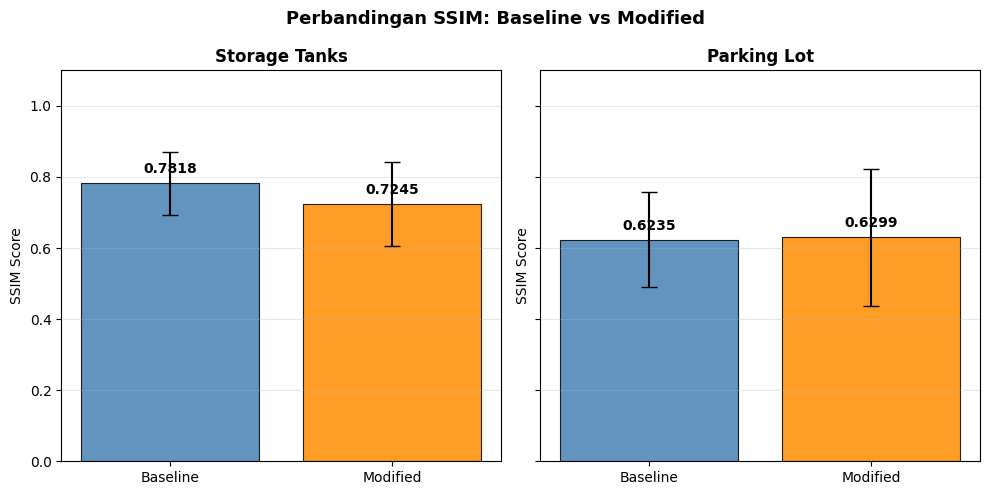

In [21]:
# Bar chart perbandingan SSIM per kelas
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
fig.suptitle('Perbandingan SSIM: Baseline vs Modified', fontweight='bold', fontsize=13)

for ax, (lbl, bm, bs, mm, ms) in zip(axes, [
    (9, ssim_b_st_mean, ssim_b_st_std, ssim_m_st_mean, ssim_m_st_std),
    (4, ssim_b_pl_mean, ssim_b_pl_std, ssim_m_pl_mean, ssim_m_pl_std),
]):
    bars = ax.bar(['Baseline', 'Modified'], [bm, mm],
                  yerr=[bs, ms], color=['steelblue', 'darkorange'],
                  alpha=0.85, capsize=6, edgecolor='black', linewidth=0.8)
    ax.set_title(CLASS_NAMES[lbl], fontweight='bold')
    ax.set_ylim(0, 1.1)
    ax.set_ylabel('SSIM Score')
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, [bm, mm]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{val:.4f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('ssim_comparison.png', dpi=120)
plt.show()

**Interpretasi Bar Chart Perbandingan SSIM:**

Grafik bar menunjukkan:
- **Storage Tanks**: Modified (0.7245) *lebih rendah* dari Baseline (0.7818), selisih -0.0574
- **Parking Lot**: Modified (0.6299) *sedikit lebih tinggi* dari Baseline (0.6235), selisih +0.0064

Error bar yang panjang pada kedua kelas (terutama Parking Lot) menunjukkan variasi SSIM antar sampel yang tinggi, artinya kualitas rekonstruksi sangat bervariasi tergantung kompleksitas gambar individu.

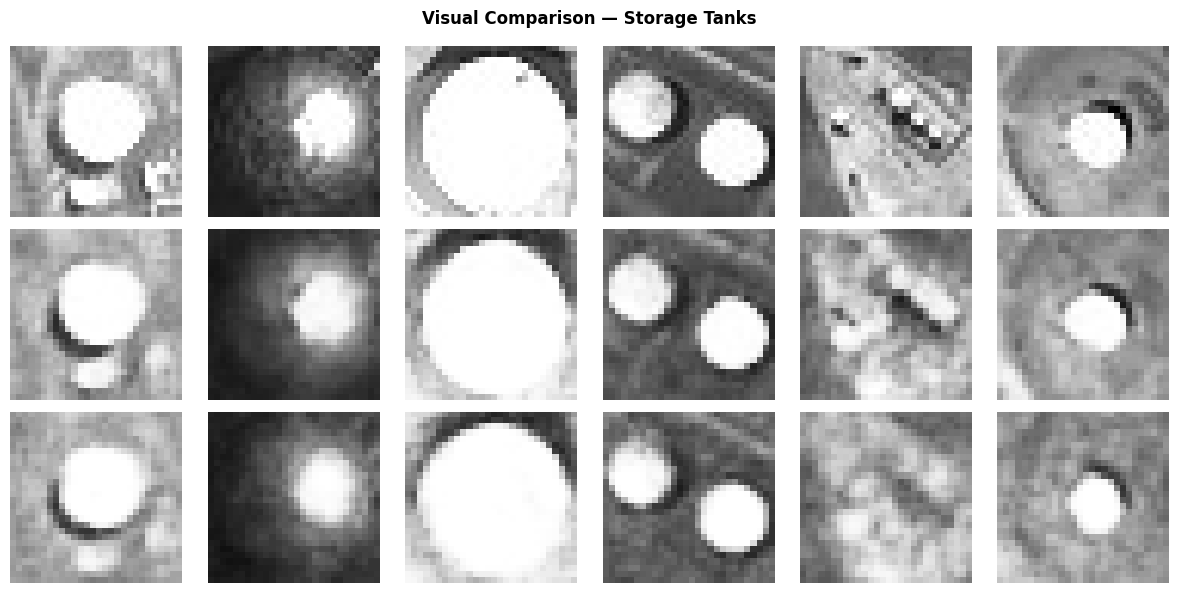

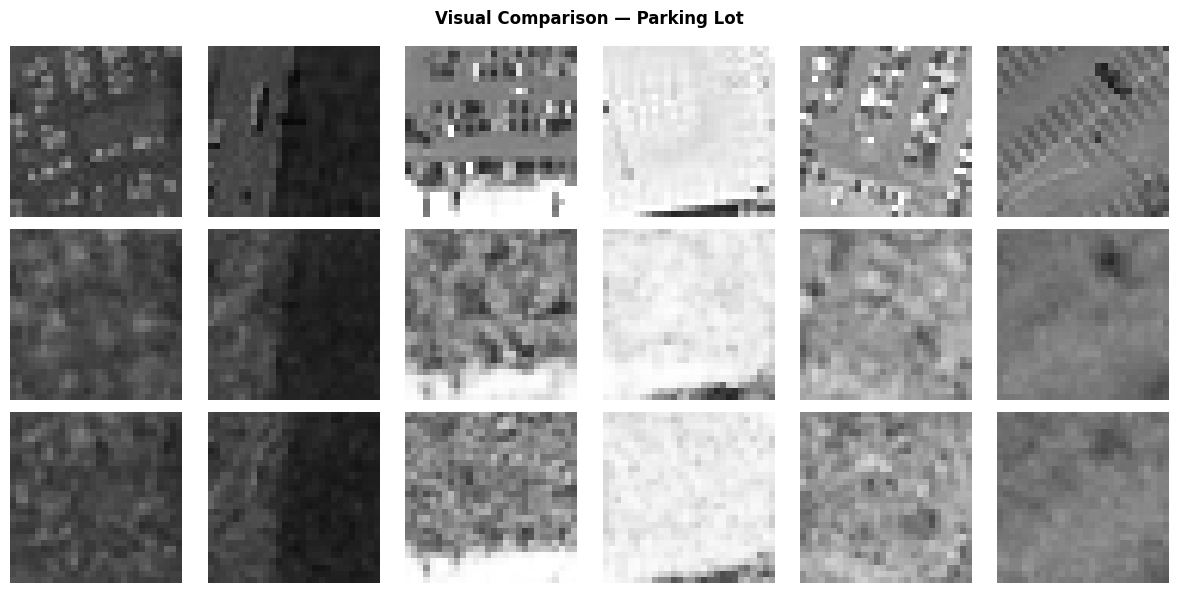

In [22]:
# Side-by-side visual: Original | Baseline | Modified per kelas
for lbl, bpred, mpred in [
    (9, pred_b_st, pred_m_st),
    (4, pred_b_pl, pred_m_pl),
]:
    cname = CLASS_NAMES[lbl]
    n = 6
    fig, axes = plt.subplots(3, n, figsize=(12, 6))
    fig.suptitle(f'Visual Comparison — {cname}', fontweight='bold', fontsize=12)
    for col in range(n):
        for row, src in enumerate([data[lbl]['X_test'], bpred, mpred]):
            axes[row, col].imshow(src[col].squeeze(), cmap='gray', vmin=0, vmax=1)
            axes[row, col].axis('off')
    axes[0,0].set_ylabel('Original',  fontsize=9, rotation=0, labelpad=55, va='center')
    axes[1,0].set_ylabel('Baseline',  fontsize=9, rotation=0, labelpad=55, va='center')
    axes[2,0].set_ylabel('Modified',  fontsize=9, rotation=0, labelpad=55, va='center')
    plt.tight_layout()
    plt.savefig(f'visual_comparison_{cname.lower().replace(" ","_")}.png', dpi=120, bbox_inches='tight')
    plt.show()

**Interpretasi Visual Comparison Storage Tanks & Parking Lot:**

**Storage Tanks:** Baris 1 (Original) vs Baris 2 (Baseline) vs Baris 3 (Modified). Baseline menghasilkan rekonstruksi yang sedikit lebih tajam pada tepi lingkaran tangki. Modified menghasilkan gambar yang sedikit lebih smooth/blurry karena efek BatchNorm dan dropout yang merata-ratakan fitur. Secara kuantitatif tercermin dari SSIM baseline yang lebih tinggi.

**Parking Lot:** Ketiga baris (Original, Baseline, Modified) terlihat sangat mirip satu sama lain, keduanya hanya berhasil merekonstruksi distribusi brightness umum tanpa detail tekstur spesifik. Perbedaan SSIM yang kecil (+0.0064) konsisten dengan persamaan visual yang terlihat.

## Kesimpulan

### Ringkasan Hasil

| Kelas | Baseline SSIM | Modified SSIM | Δ |
|-------|--------------|---------------|---|
| Storage Tanks | 0.7818 ± 0.0892 | 0.7245 ± 0.1174 | -0.0574 ↓ |
| Parking Lot | 0.6235 ± 0.1339 | 0.6299 ± 0.1576 | +0.0064 ↑ |

### Analisis Hasil

**Storage Tanks Baseline lebih unggul (SSIM 0.7818 vs 0.7245)**

Modified model justru menghasilkan SSIM lebih rendah untuk Storage Tanks. Hal ini dapat dijelaskan oleh beberapa faktor:

1. **Kapasitas model terlalu besar untuk dataset ini.** Modified model memiliki jauh lebih banyak parameter (stacked Conv 32→64, FC 1024). Dengan 6.400 sampel training, model lebih mudah overfit terlihat dari gap train-val loss yang membesar di grafik training history.
2. **Dropout dan BatchNorm menyebabkan over-smoothing.** Untuk kelas Storage Tanks yang memiliki fitur dominan berupa tepi lingkaran tajam, regularisasi yang terlalu kuat justru menghaluskan detail tersebut sehingga rekonstruksi menjadi lebih blur.
3. **Loss function MSE vs BCE.** Meskipun MSE secara teori lebih berkorelasi dengan SSIM, pada praktiknya untuk citra dengan kontras tinggi (putih-hitam tajam seperti tangki), BCE bisa lebih efektif dalam mempertahankan ketajaman tepi.

**Parking Lot Modified sedikit lebih baik (SSIM 0.6299 vs 0.6235)**

Modified model berhasil memberi sedikit peningkatan pada Parking Lot, meskipun sangat kecil (+0.0064). Stacked Conv yang lebih dalam sedikit membantu menangkap variasi tekstural Parking Lot yang heterogen. Namun peningkatannya marginal karena:
- Kompleksitas visual Parking Lot sangat tinggi — detail kendaraan dan garis parkir sulit direpresentasikan dalam 128 dimensi
- Overfitting terlihat jelas dari kurva training (train loss jauh lebih rendah dari val loss)

### Kesimpulan Dimension Reduction

Kedua model baseline dan modified berhasil melakukan kompresi gambar dari **784 dimensi** (28×28 piksel) menjadi **128 dimensi**, rasio kompresi **6.125×**. Kualitas rekonstruksi bervariasi antar kelas:
- **Storage Tanks** lebih mudah direkonstruksi (SSIM ~0.78) karena memiliki fitur geometris yang konsisten (lingkaran)
- **Parking Lot** lebih sulit direkonstruksi (SSIM ~0.62) karena tekstur yang kompleks dan heterogen

Untuk dataset ini, **Baseline Autoencoder sudah cukup optimal** khususnya untuk Storage Tanks. Peningkatan lebih lanjut bisa dicapai dengan: menambah jumlah data augmentasi, menggunakan arsitektur encoder yang lebih dalam namun dengan regularisasi lebih ringan, atau mencoba latent dimension yang lebih besar dari 128 untuk kelas kompleks seperti Parking Lot.

In [23]:
# Simpan model
baseline_st.save('baseline_storage_tanks.keras')
baseline_pl.save('baseline_parking_lot.keras')
best_st['model'].save('modified_storage_tanks.keras')
best_pl['model'].save('modified_parking_lot.keras')
print('4 model tersimpan.')

4 model tersimpan.
